<a href="https://colab.research.google.com/github/haricharansai/Deep-Learning-With-Accelerated-Computing-2.2/blob/main/VisionPort_Vehicle_Detection.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [ ]:
!pip install -q ultralytics opencv-python


In [ ]:
from ultralytics import YOLO
from google.colab import files
from IPython.display import display
from PIL import Image
from collections import Counter
import cv2
import os

# Load pretrained YOLO11 Small model
model = YOLO("yolo11s.pt")

print("VisionPort YOLO11 Small model loaded successfully!")

VisionPort YOLO11 Small model loaded successfully!


In [ ]:
uploaded = files.upload()

image_path = next(iter(uploaded.keys()))

print("Uploaded:", image_path)

Saving traffic photo.jpg to traffic photo (2).jpg
Uploaded: traffic photo (2).jpg



image 1/1 /content/traffic photo (2).jpg: 480x640 19 cars, 4 buss, 425.8ms
Speed: 3.2ms preprocess, 425.8ms inference, 1.6ms postprocess per image at shape (1, 3, 480, 640)
Results saved to /content/runs/detect/predict-3


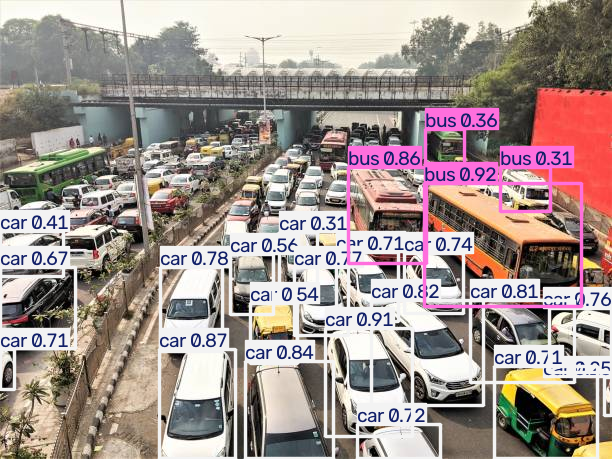

In [ ]:
# COCO vehicle class IDs
vehicle_classes = [1, 2, 3, 5, 7]

# Run vehicle detection
results = model.predict(
    source=image_path,
    conf=0.25,
    classes=vehicle_classes,
    save=True
)

# Get detection result
result = results[0]

# Display annotated image
annotated_image = result.plot()

display(Image.fromarray(
    cv2.cvtColor(annotated_image, cv2.COLOR_BGR2RGB)
))

In [ ]:
vehicle_names = {
    1: "Bicycle",
    2: "Car",
    3: "Motorcycle",
    5: "Bus",
    7: "Truck"
}

counts = Counter()

for box in result.boxes:
    class_id = int(box.cls[0])
    counts[vehicle_names[class_id]] += 1

print("\n========== VISIONPORT REPORT ==========")

total = sum(counts.values())

for vehicle, count in counts.items():
    print(f"{vehicle}: {count}")

print("---------------------------------------")
print("Total Vehicles Detected:", total)
print("=======================================")


========== VISIONPORT REPORT ==========
Bus: 4
Car: 19
---------------------------------------
Total Vehicles Detected: 23
